#### Exploratory Data Analysis (EDA) Fundamentals
Exploratory Data Analysis (EDA) is the crucial phase where we analyze datasets to summarize their main characteristics, often using statistical graphics and data visualization methods.

### Key Learning Objectives:
1. Calculate central tendencies, dispersion, and **skewness**.
2. Visualize individual feature distributions using **Histograms** and **KDE (Kernel Density Estimation)**.
3. Detect statistical outliers visually using **Boxplots**.
4. Identify missing value patterns visually before applying cleaning transformations.

In [ ]:
# Setup & Sample Dataset
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

# Generate synthetic dataset with realistic skewed distributions & missingness
np.random.seed(42)
n_samples = 200

data = {
    "age": np.random.normal(loc=35, scale=8, size=n_samples).round(),
    "income": np.random.exponential(scale=50000, size=n_samples) + 20000,  # Right-skewed
    "credit_score": np.random.uniform(low=300, high=850, size=n_samples),
    "churn": np.random.choice([0, 1], size=n_samples, p=[0.8, 0.2]),
}

df_eda = pd.DataFrame(data)

# Inject intentional missing values for visual detection demo
df_eda.loc[df_eda.sample(frac=0.10, random_state=42).index, "income"] = np.nan
df_eda.loc[df_eda.sample(frac=0.05, random_state=42).index, "credit_score"] = np.nan

print("--- Data Sample ---")
print(df_eda.head())

---
## 1. Summary Statistics & Skewness Analysis

* **Mean vs. Median**: If $\text{Mean} > \text{Median}$, the feature is **right-skewed** (positively skewed).
* **Skewness Thresholds**:
  * Between $-0.5$ and $0.5$: Fairly symmetrical.
  * $> 1.0$ or $< -1.0$: Highly skewed (may require log transformation).

* Skewness answers: "Is my data pulled more to the left or to the right?"
* Think of skewness as a measure of how asymmetric or "lopsided" your data is compared to a classic, perfectly balanced bell curve.
* When you run df_eda.skew(), Pandas calculates a single number for each numerical column.
1. Zero Skew (Symmetrical) — Value $\approx 0$
2. Positive Skew (Right-Skewed) — Value $> 0$
3. Negative Skew (Left-Skewed) — Value $< 0$

| Skewness Value | Interpretation | What to do in Data Cleaning? |
| :--- | :--- | :--- |
| **$-0.5$ to $0.5$** | Fairly Symmetrical | Great as-is! Safe to use **Mean** for imputation. |
| **$0.5$ to $1.0$** (or $-0.5$ to $-1.0$) | Moderately Skewed | Consider using **Median** instead of Mean for imputation. |
| **$> 1.0$** (or $< -1.0$) | Highly Skewed | Definitely use **Median** for imputation, and consider applying a log transformation if using linear algorithms. |


In [ ]:
stats_summary = df_eda.describe().T
print(stats_summary.head())
stats_summary["skewness"] = df_eda.skew(numeric_only=True)
print("--- Comprehensive Statistical Summary ---")
print(stats_summary[["mean", "std", "50%", "min", "max", "skewness"]])

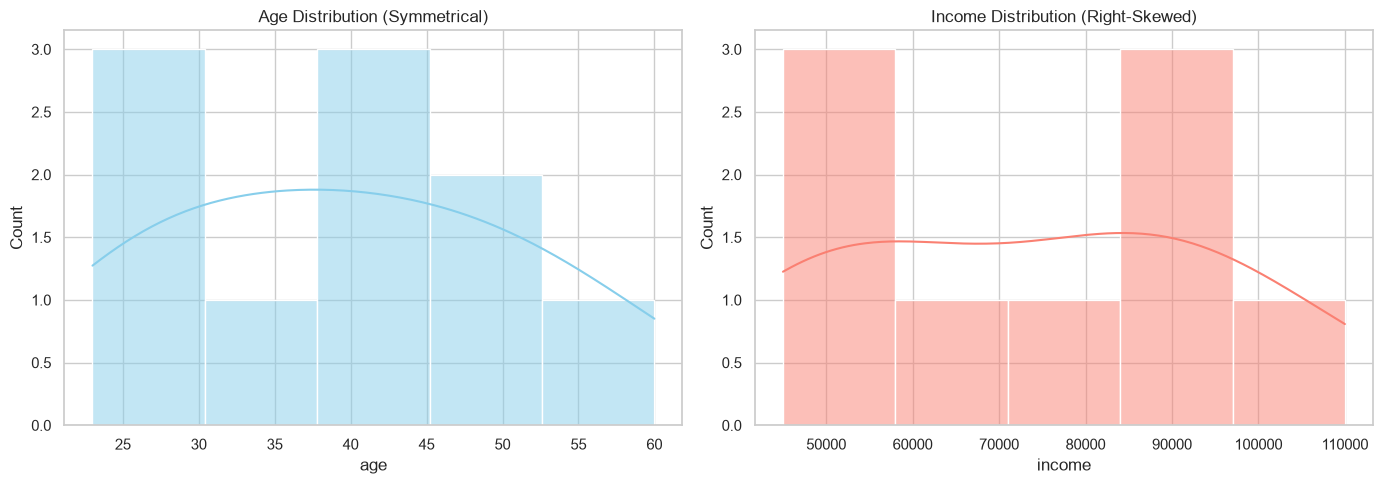

In [6]:
# Distribution Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Symmetrical Distribution
sns.histplot(df_eda["age"], kde=True, ax=axes[0], color="skyblue")
axes[0].set_title("Age Distribution (Symmetrical)")

# Right-Skewed Distribution
sns.histplot(df_eda["income"], kde=True, ax=axes[1], color="salmon")
axes[1].set_title("Income Distribution (Right-Skewed)")

plt.tight_layout()
plt.show()

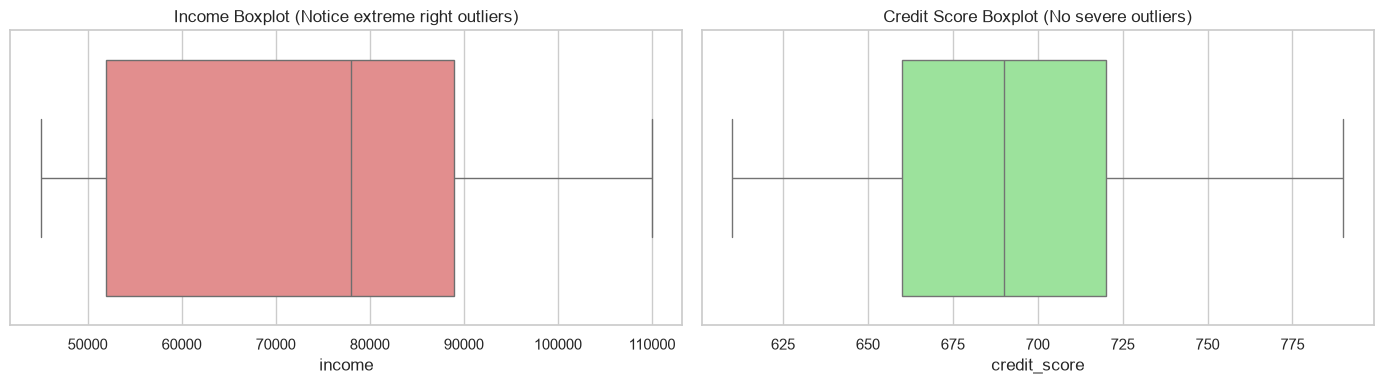

In [7]:
# Boxplot Outlier Detection
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.boxplot(x=df_eda["income"], ax=axes[0], color="lightcoral")
axes[0].set_title("Income Boxplot (Notice extreme right outliers)")

sns.boxplot(x=df_eda["credit_score"], ax=axes[1], color="lightgreen")
axes[1].set_title("Credit Score Boxplot (No severe outliers)")

plt.tight_layout()
plt.show()

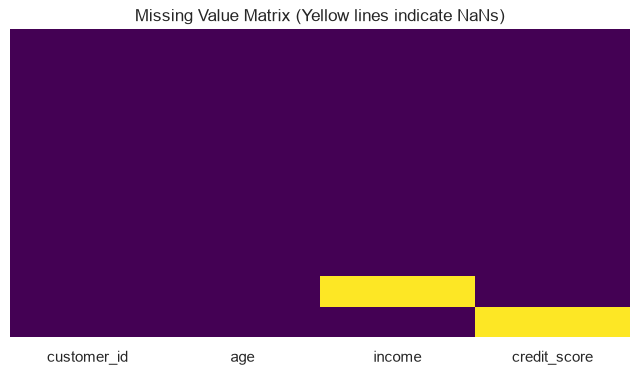

In [8]:
# Missingness Heatmap

plt.figure(figsize=(8, 4))
sns.heatmap(df_eda.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Missing Value Matrix (Yellow lines indicate NaNs)")
plt.show()